# W7D4 — Text-to-Speech — Lab

**Week 7 · Day 4 · Vision, language and speech** · Lab

<a href="https://colab.research.google.com/github/0xRush/AIEP_Olo_student/blob/master/week_7_multimodal/labs/D4_text_to_speech/D4_text_to_speech_blank.ipynb" target="_blank">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **The big idea.** Yesterday ran sound → spectrogram → text. Text-to-speech runs it **backwards**:
> text → (a spectrogram) → sound. And since there is no single right way to say a sentence, the
> hardest question is not *how* to generate speech but **how to measure it** — so today you use
> yesterday's Whisper as the judge.

You will make two models talk, in English and Arabic; open one of them into its two stages (text →
mel spectrogram → waveform); change its voice; find the text that breaks it — numbers, abbreviations,
symbols — and fix that text before the model ever sees it.

<div dir="rtl" align="right">

# W7D4 — تحويل النص إلى كلام

**الأسبوع السابع · اليوم الرابع · الرؤية واللغة والكلام** · معمل

<a href="https://colab.research.google.com/github/0xRush/AIEP_Olo_student/blob/master/week_7_multimodal/labs/D4_text_to_speech/D4_text_to_speech_blank.ipynb" target="_blank">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **الفكرة الكبرى.** سار الأمس من الصوت إلى المخطّط الطيفي إلى النص. ويسير تحويل النص إلى كلام **بالعكس**: نصّ ←
> (مخطّط طيفي) ← صوت. ولأنه لا توجد طريقة صحيحة واحدة لنطق جملة، فأصعب سؤال ليس *كيف* نولّد الكلام بل **كيف
> نقيسه** — لذلك تستعمل اليوم Whisper الأمس حَكَمًا.

ستجعل نموذجين يتكلّمان، بالإنجليزية والعربية؛ وتفتح أحدهما إلى مرحلتيه (نصّ ← مخطّط طيفي ← موجة)؛ وتغيّر صوته؛
وتجد النص الذي يكسره — الأعداد والاختصارات والرموز — وتُصلح ذلك النص قبل أن يراه النموذج أصلًا.

</div>

> **This is your lab notebook.** Work through the hints — they tell you what to do and where
> to look, not what to type. Stuck for more than ten minutes on one task? Open the `_guided`
> version. That is not cheating; sitting stuck in silence is the only mistake. The full
> solution is released at the end of the day.

<div dir="rtl" align="right">

> **هذا دفتر المعمل الخاص بك.** اعمل وفق الإرشادات — فهي تخبرك بما يجب فعله وأين تبحث، لا بما
> تكتبه حرفيًا. إذا توقّفت أكثر من عشر دقائق عند مهمة واحدة فافتح نسخة `_guided`؛ هذا ليس غشًّا،
> والخطأ الوحيد هو أن تبقى متوقّفًا بصمت. ويُنشر الحل الكامل في نهاية اليوم.

</div>

## Learning objectives

- Generate English and Arabic speech with a small TTS model and listen to it.
- See what a TTS model actually reads, and why digits and symbols come out wrong.
- Write a **text normaliser** that turns `$1,999` into words before synthesis.
- Split a TTS model into its two stages: an acoustic model (text → mel spectrogram) and a
  **vocoder** (mel spectrogram → waveform).
- Change the voice with a speaker embedding, and the rhythm with the random seed.
- Score synthetic speech automatically with a speech-to-text round trip, and compare it with real
  speech of the same sentences.

<div dir="rtl" align="right">

## أهداف التعلّم

- أن تولّد كلامًا إنجليزيًا وعربيًا بنموذج صغير لتحويل النص إلى كلام وتستمع إليه.
- أن ترى ما يقرؤه نموذج تحويل النص إلى كلام فعلًا، ولماذا تخرج الأرقام والرموز خاطئة.
- أن تكتب **مُوحِّد نصوص** يحوّل `$1,999` إلى كلمات قبل التوليد.
- أن تقسم النموذج إلى مرحلتيه: نموذج صوتي (نصّ ← مخطّط طيفي على مقياس ميل) و**مُرمِّز صوتي** (vocoder: مخطّط
  طيفي ← موجة).
- أن تغيّر الصوت بتضمين متحدّث، والإيقاعَ بالبذرة العشوائية.
- أن تقيّم الكلام المولَّد آليًا برحلة ذهاب وإياب عبر تحويل الكلام إلى نص، وتقارنه بكلام حقيقي للجمل نفسها.

</div>

## About the models and data

**Models** (downloaded once, then cached):

| model | what it is | size |
|---|---|---|
| `facebook/mms-tts-eng`, `facebook/mms-tts-ara` | MMS-TTS (VITS): text straight to waveform, one model per language | 145 MB each |
| `microsoft/speecht5_tts` + `microsoft/speecht5_hifigan` | SpeechT5: text → mel spectrogram, then a HiFi-GAN vocoder → waveform | 585 + 50 MB |
| `openai/whisper-base` | yesterday's speech-to-text model, used as the judge | 290 MB |

MMS-TTS is licensed **CC BY-NC 4.0**: fine for learning, not for a product.

**Data:** `speech_clips_small` again. Its transcripts are today's input text — so the synthetic
speech can be compared with **real people reading the same sentences**. It also holds `voices.npz`:
four speaker embeddings (*x-vectors*) from the CMU Arctic corpus, two female (`slt`, `clb`) and two
male (`bdl`, `rms`), 512 numbers each.

The notebook takes about three minutes of computing on a laptop CPU.

<div dir="rtl" align="right">

## عن النماذج والبيانات

**النماذج** (تُنزَّل مرّة ثم تُحفظ):

| النموذج | ما هو | الحجم |
|---|---|---|
| `facebook/mms-tts-eng` و`facebook/mms-tts-ara` | ‏MMS-TTS ‏(VITS): من النص إلى الموجة مباشرةً، نموذج لكل لغة | ‏١٤٥ ميجابايت لكلٍّ |
| `microsoft/speecht5_tts` + `microsoft/speecht5_hifigan` | ‏SpeechT5: نصّ ← مخطّط طيفي، ثم مُرمِّز صوتي HiFi-GAN ← موجة | ‏٥٨٥ + ٥٠ ميجابايت |
| `openai/whisper-base` | نموذج تحويل الكلام إلى نص من الأمس، حَكَمًا | ‏٢٩٠ ميجابايت |

ترخيص MMS-TTS هو **CC BY-NC 4.0**: يصلح للتعلّم، لا لمنتج.

**البيانات:** `speech_clips_small` مرّة أخرى. نصوصه هي مُدخل اليوم — فيُقارَن الكلام المولَّد بـ**أشخاص حقيقيين
يقرؤون الجمل نفسها**. وفيه أيضًا `voices.npz`: أربعة تضمينات متحدّثين (*x-vectors*) من مدوّنة CMU Arctic، اثنان
لإناث (`slt` و`clb`) واثنان لذكور (`bdl` و`rms`)، ‏٥١٢ عددًا لكلٍّ منها.

يستغرق الدفتر نحو ثلاث دقائق من الحساب على معالج حاسوب محمول.

</div>

## Setup

Run this first. On Colab it installs the course package; locally it uses your checkout. It also
loads yesterday's tools: `transcribe()` with Whisper-base, `wer()`, and the two text normalisers.

<div dir="rtl" align="right">

## الإعداد

شغّل هذه الخلية أولًا. على Colab تُثبّت حزمة المقرّر، ومحلّيًا تستعمل نسختك من المستودع. وتُحمّل أيضًا أدوات الأمس:
`transcribe()` مع Whisper-base، و`wer()`، ومُوحِّدَي النصوص.

</div>

In [1]:
# === AIEP portable setup — works locally and on Google Colab ========================
try:
    import aiep
except ImportError:
    import subprocess, sys
    from pathlib import Path
    _local = next((p / "shared" for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "shared" / "aiep").is_dir()), None)
    if _local:
        sys.path.insert(0, str(_local))
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "git+https://github.com/0xRush/AIEP_Olo_student.git#subdirectory=shared"])
    import aiep

from aiep.env import ensure, seed_everything, device, versions
ensure('transformers', 'torch', 'soundfile', 'sentencepiece', 'matplotlib', 'pandas')
seed_everything(42)

from aiep.data import get_dataset_dir
from aiep.paths import ARTEFACT_DIR
from aiep.checks import check, report

import re
import time

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import matplotlib.pyplot as plt
import transformers
from IPython.display import Audio, display
from transformers import WhisperForConditionalGeneration, WhisperProcessor

torch.set_grad_enabled(False)
transformers.logging.set_verbosity_error()
SEED, RATE = 42, 16_000

ROOT = get_dataset_dir("speech_clips_small")
CLIPS = pd.read_csv(ROOT / "transcripts.csv")
EN = CLIPS[CLIPS.file.str.startswith("en/")].reset_index(drop=True)
AR = CLIPS[CLIPS.file.str.startswith("ar/")].reset_index(drop=True)
VOICES = dict(np.load(ROOT / "voices.npz"))

# ── yesterday's tools, unchanged ────────────────────────────────────────────────────────
judge_processor = WhisperProcessor.from_pretrained("openai/whisper-base")
judge = WhisperForConditionalGeneration.from_pretrained("openai/whisper-base").eval()


def transcribe(audio, language="english"):
    """Whisper-base's transcript of 16 kHz audio."""
    features = judge_processor(audio, sampling_rate=RATE, return_tensors="pt").input_features
    ids = judge.generate(features, language=language, task="transcribe")
    return judge_processor.batch_decode(ids, skip_special_tokens=True)[0].strip()


def wer(reference, hypothesis):
    """Word error rate, by word-level edit distance (D3 task 3)."""
    ref, hyp = reference.split(), hypothesis.split()
    d = np.zeros((len(ref) + 1, len(hyp) + 1), dtype=int)
    d[:, 0], d[0, :] = np.arange(len(ref) + 1), np.arange(len(hyp) + 1)
    for i in range(1, len(ref) + 1):
        for j in range(1, len(hyp) + 1):
            d[i, j] = min(d[i - 1, j] + 1, d[i, j - 1] + 1, d[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]))
    return float(d[-1, -1] / len(ref))


def normalise_en(text):
    return " ".join(re.sub(r"[^a-z' ]", " ", text.lower()).split())


def normalise_arabic(text):
    text = re.sub(r"[ً-ْٰـ]", "", text)
    text = re.sub(r"[أإآٱ]", "ا", text)
    text = text.replace("ة", "ه").replace("ى", "ي")
    return " ".join(re.sub(r"[^\w\s]", " ", text).split())


print(f"{len(EN)} English and {len(AR)} Arabic sentences | voices: {list(VOICES)}")
print(versions(), "| device:", device())

⬇️  Downloading speech_clips_small.zip (10.52 MB) …
✅ speech_clips_small: downloaded to /content/aiep_data/speech_clips_small.zip
📦 speech_clips_small: extracted 55 file(s) to /content/aiep_data/_extracted/speech_clips_small


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'TypeError: Failed to fetch'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  290MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.81k [00:00<?, ?B/s]

30 English and 20 Arabic sentences | voices: ['slt', 'clb', 'bdl', 'rms']
python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | torch 2.11.0+cpu | transformers 5.20.2 | device: cpu


## Section 1 — Warm-up: make it talk  *(~10 min)*

Nothing to write. MMS-TTS reads one English and one Arabic sentence from the dataset. Listen to both,
and to the real recording of the English one. The `speak` helper is what the rest of the lab uses.

<div dir="rtl" align="right">

## القسم ١ — إحماء: اجعله يتكلّم  *(≈١٠ دقائق)*

لا شيء تكتبه. يقرأ MMS-TTS جملة إنجليزية وجملة عربية من البيانات. استمع إليهما، وإلى التسجيل الحقيقي للجملة
الإنجليزية. والدالة المساعدة `speak` هي ما يستعمله باقي المعمل.

</div>

In [2]:
from transformers import AutoTokenizer, VitsModel

MMS = {lang: (AutoTokenizer.from_pretrained(f"facebook/mms-tts-{lang}"),
              VitsModel.from_pretrained(f"facebook/mms-tts-{lang}").eval()) for lang in ["eng", "ara"]}


def speak(text, lang="eng", seed=SEED):
    """MMS-TTS speech for `text`, as 16 kHz float32 samples."""
    tokenizer, model = MMS[lang]
    torch.manual_seed(seed)                     # VITS draws random noise: fix it to repeat a result
    return model(**tokenizer(text, return_tensors="pt")).waveform[0].numpy()


english, arabic = speak(EN.text[1]), speak(AR.text[0], "ara")
print("synthetic :", EN.text[1]); display(Audio(english, rate=RATE))
print("real      :", EN.text[1]); display(Audio(sf.read(ROOT / EN.file[1])[0], rate=RATE))
print("synthetic :", AR.text[0]); display(Audio(arabic, rate=RATE))

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/47.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

synthetic : if she could only see phronsie for just one moment


real      : if she could only see phronsie for just one moment


synthetic : ومع هذا فمعظم الإشارات يتم التعبير عنها باللغة الكاتالونية لأنها وبموجب القانون تعتبر اللغة الرسمية الأولى.


## Section 2 — Inside a TTS pipeline  *(~55 min)*

Five tasks:

1. **What the model reads** — characters, and what happens to the ones it never learned to say.
2. **A text normaliser** — turn numbers and symbols into words first.
3. **Stage one: text → mel spectrogram** — yesterday's picture, made instead of read.
4. **Stage two: the vocoder** — mel spectrogram → waveform.
5. **Voices and variation** — four speakers, and three takes of one sentence.

<div dir="rtl" align="right">

## القسم ٢ — داخل خطّ تحويل النص إلى كلام  *(≈٥٥ دقيقة)*

خمس مهام:

١. **ما يقرؤه النموذج** — الحروف، وما يحدث لتلك التي لم يتعلّم نطقها قط.
٢. **مُوحِّد نصوص** — حوّل الأعداد والرموز إلى كلمات أولًا.
٣. **المرحلة الأولى: نصّ ← مخطّط طيفي** — صورة الأمس، تُصنع بدل أن تُقرأ.
٤. **المرحلة الثانية: المُرمِّز الصوتي** — مخطّط طيفي ← موجة.
٥. **الأصوات والتنوّع** — أربعة متحدّثين، وثلاث قراءات لجملة واحدة.

</div>

### Task 1 — What does the model read?

A TTS model reads **characters**, not words: its tokenizer has a few dozen symbols. Tokenise the
sentences below, decode the ids back to text, and compare with what you gave it. Then listen, and let
Whisper say what it heard. MMS-TTS was trained on text with every number already written as words, so
it never learned to say `1999` — in Arabic the digits are simply dropped.

<div dir="rtl" align="right">

### المهمّة ١ — ماذا يقرأ النموذج؟

يقرأ نموذج تحويل النص إلى كلام **الحروف** لا الكلمات: في مُقطِّعه بضع عشرات من الرموز. قطّع الجمل أدناه، وفكّ
ترميز المعرّفات إلى نص، وقارن بما أعطيته. ثم استمع، ودع Whisper يقول ما سمعه. دُرّب MMS-TTS على نصوص كُتب فيها كل
عدد بالكلمات، فلم يتعلّم قط أن ينطق `1999` — وفي العربية تسقط الأرقام ببساطة.

</div>

In [19]:
# ────────────────────────────────────────────────────────────────────
# 1) ids = tokenizer(text, return_tensors="pt").input_ids
# 2) tokenizer.decode(ids[0]) shows the text the model really receives.
#
# ١) `ids = tokenizer(text, return_tensors="pt").input_ids`
# ٢) `tokenizer.decode(ids[0])` يُظهر النص الذي يتلقّاه النموذج فعلًا.
# ────────────────────────────────────────────────────────────────────

TRICKY = {"eng": "Dr. Smith paid $1,999 on 3/4/2025.", "ara": "دفع الدكتور سمير 1999 ريالًا."}
SEEN = {}
for lang, text in TRICKY.items():
    tokenizer, _ = MMS[lang]
    print(f"{lang}: {len(tokenizer)} symbols in the vocabulary")
    ids = tokenizer(text, return_tensors="pt").input_ids

    SEEN[lang] = tokenizer.decode(ids[0])

    # TODO: Tokenise `text`, decode the ids back into SEEN[lang], and print both.
    # مهمة: قطّع `text`، وفكّ ترميز المعرّفات إلى `SEEN[lang]`، واطبع الاثنين

    print(f"  you wrote   : {text}")
    print(f"  model reads : {SEEN[lang]}")
    print(f"  you wrote   : {text}")
    print(f"  model reads : {SEEN[lang]}")
    speech = speak(text, lang)
    print(f"  whisper hears: {transcribe(speech, 'english' if lang == 'eng' else 'arabic')}")
    display(Audio(speech, rate=RATE))

eng: 39 symbols in the vocabulary
  you wrote   : Dr. Smith paid $1,999 on 3/4/2025.
  model reads : dr smith paid 1 on 342025
  you wrote   : Dr. Smith paid $1,999 on 3/4/2025.
  model reads : dr smith paid 1 on 342025
  whisper hears: We submit paid who long worth them.


ara: 40 symbols in the vocabulary
  you wrote   : دفع الدكتور سمير 1999 ريالًا.
  model reads : دفع الدكتور سمير  ريالا
  you wrote   : دفع الدكتور سمير 1999 ريالًا.
  model reads : دفع الدكتور سمير  ريالا
  whisper hears: فعد دكتور السمير واريالة


### Task 2 — Normalise the text first

Every real TTS system has a **text normaliser** in front of the model that writes out what a person
would *say*. Write a small English one: drop thousands separators, turn `$N` into `N dollars`, expand
`Dr.` and `Mr.`, and replace every number by its words with the `say_number` helper.

<div dir="rtl" align="right">

### المهمّة ٢ — وحّد النص أولًا

في كل نظام حقيقي لتحويل النص إلى كلام **مُوحِّد نصوص** أمام النموذج يكتب ما *يقوله* الإنسان. اكتب واحدًا صغيرًا
للإنجليزية: احذف فواصل الآلاف، وحوّل `$N` إلى `N dollars`، ووسّع `Dr.` و`Mr.`، واستبدل بكل عدد كلماته بالدالة
المساعدة `say_number`.

</div>

In [30]:
# ────────────────────────────────────────────────────────────────────
# 1) re.sub(r"(\d),(\d)", r"\1\2", text) removes the comma in 1,999.
# 2) re.sub(r"\$(\d+)", r"\1 dollars", text) moves the dollar sign after the number.
# 3) re.sub(r"\d+", lambda m: say_number(int(m.group())), text) writes every number out.
#
# ١) `re.sub(r"(\d),(\d)", r"\1\2", text)` يحذف الفاصلة في 1,999.
# ٢) `re.sub(r"\$(\d+)", r"\1 dollars", text)` ينقل علامة الدولار بعد العدد.
# ٣) `re.sub(r"\d+", lambda m: say_number(int(m.group())), text)` يكتب كل عدد بالكلمات.
# ────────────────────────────────────────────────────────────────────

ONES = ("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen "
        "fifteen sixteen seventeen eighteen nineteen").split()
TENS = "- - twenty thirty forty fifty sixty seventy eighty ninety".split()


def say_number(n):
    """0 <= n < 1,000,000 in English words."""
    if n < 20:
        return ONES[n]
    if n < 100:
        return TENS[n // 10] + ("" if n % 10 == 0 else " " + ONES[n % 10])
    if n < 1000:
        return ONES[n // 100] + " hundred" + ("" if n % 100 == 0 else " " + say_number(n % 100))
    return say_number(n // 1000) + " thousand" + ("" if n % 1000 == 0 else " " + say_number(n % 1000))


def normalise(text):
    """Write out what a person would say: titles, money and numbers as words."""
    # TODO: Remove thousands commas, turn "$N" into "N dollars", then replace every number with say_number.
    # مهمة: احذف فواصل الآلاف، وحوّل `"$N"` إلى `"N dollars"`، ثم استبدل بكل عدد `say_number`

    text = text.replace("Dr.", "doctor")
    text = text.replace("Mr.", "mister")

    text = re.sub(r"(\d),(\d)", r"\1\2", text)

    text = re.sub(r"\$(\d+)", r"\1 dollars", text)

    text = re.sub(
        r"\d+",
        lambda m: say_number(int(m.group())),
        text
    )

    return text

SPOKEN = normalise(TRICKY["eng"])
print("before:", TRICKY["eng"])
print("after :", SPOKEN)
FIXED_HEARD = transcribe(speak(SPOKEN))
print("whisper hears:", FIXED_HEARD)
display(Audio(speak(SPOKEN), rate=RATE))

before: Dr. Smith paid $1,999 on 3/4/2025.
after : doctor Smith paid one thousand nine hundred ninety nine dollars on three/four/two thousand twenty five.
whisper hears: Bokdler Smith paid $1,999 on $342,025.


### Task 3 — Stage one: text → mel spectrogram

MMS-TTS hides its stages inside one model. **SpeechT5** shows them. Its acoustic model reads the text
and a **speaker embedding** (whose voice to use) and writes a mel spectrogram: 80 numbers per 16 ms
frame — the same kind of picture Whisper read yesterday. Generate it with `generate_speech` and **no
vocoder**, and draw it next to the spectrogram of a real person saying the same sentence.

<div dir="rtl" align="right">

### المهمّة ٣ — المرحلة الأولى: نصّ ← مخطّط طيفي

يُخفي MMS-TTS مراحله داخل نموذج واحد. أما **SpeechT5** فيُظهرها. يقرأ نموذجه الصوتي النص و**تضمين متحدّث** (بأيّ
صوت يتكلّم) ويكتب مخطّطًا طيفيًا على مقياس ميل: ‏٨٠ عددًا لكل إطار من ١٦ مللي ثانية — نوع الصورة نفسه الذي قرأه
Whisper أمس. ولّده بـ`generate_speech` **دون مُرمِّز صوتي**، وارسمه بجانب المخطّط الطيفي لشخص حقيقي يقول الجملة
نفسها.

</div>

In [9]:
from transformers import SpeechT5ForTextToSpeech, SpeechT5HifiGan, SpeechT5Processor

t5_processor = SpeechT5Processor.from_pretrained("microsoft/speecht5_tts")
t5 = SpeechT5ForTextToSpeech.from_pretrained("microsoft/speecht5_tts").eval()
vocoder = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").eval()
SENTENCE = EN.text[1]

preprocessor_config.json:   0%|          | 0.00/433 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.06k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/232 [00:00<?, ?B/s]

spm_char.model: reconstructing file:   0%|          |  0.00B /  238kB            

spm_char.model: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 50.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/158 [00:00<?, ?it/s]

generated mel spectrogram: (198, 80) = 198 frames x 80 mel bands


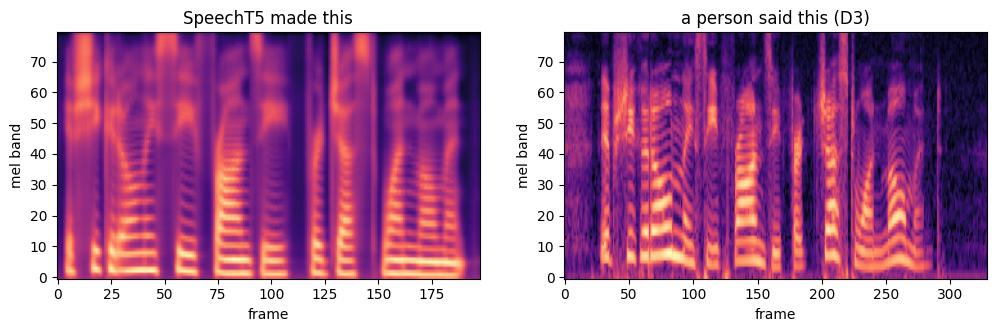

In [21]:
# ────────────────────────────────────────────────────────────────────
# 1) inputs = t5_processor(text=SENTENCE, return_tensors="pt")
# 2) speaker = torch.tensor(VOICES["slt"])[None] — shape (1, 512).
# 3) MEL = t5.generate_speech(inputs["input_ids"], speaker) — with no vocoder it returns (frames, 80).
#
# ١) `inputs = t5_processor(text=SENTENCE, return_tensors="pt")`
# ٢) `speaker = torch.tensor(VOICES["slt"])[None]` — بالشكل `(1, 512)`.
# ٣) `MEL = t5.generate_speech(inputs["input_ids"], speaker)` — دون مُرمِّز صوتي يُعيد `(frames, 80)`.
# ────────────────────────────────────────────────────────────────────

# TODO: Make a (1, 512) speaker tensor from VOICES["slt"] and generate the mel spectrogram MEL, with no vocoder.
# مهمة: اصنع موتر متحدّث `(1, 512)` من `VOICES["slt"]` وولّد المخطّط الطيفي `MEL` دون مُرمِّز صوتي.
inputs = t5_processor(
    text=SENTENCE,
    return_tensors="pt"
)

speaker = torch.tensor(
    VOICES["slt"]
)[None]

MEL = t5.generate_speech(
    inputs["input_ids"],
    speaker
)
print("generated mel spectrogram:", tuple(MEL.shape), f"= {MEL.shape[0]} frames x 80 mel bands")

real = sf.read(ROOT / EN.file[1], dtype="float32")[0]
REAL_MEL = judge_processor(real, sampling_rate=RATE, return_tensors="pt").input_features[0, :, :len(real) // 160]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].imshow(MEL.T, origin="lower", aspect="auto", cmap="magma"); axes[0].set_title("SpeechT5 made this")
axes[1].imshow(REAL_MEL, origin="lower", aspect="auto", cmap="magma"); axes[1].set_title("a person said this (D3)")
for ax in axes:
    ax.set_xlabel("frame"); ax.set_ylabel("mel band")
plt.show()

### Task 4 — Stage two: the vocoder

A spectrogram has no phase, so it cannot be played. The **vocoder** — here HiFi-GAN, a neural
network trained to invert spectrograms — turns it into a waveform. Run it, check the length (it adds
256 samples per frame), and listen.

<div dir="rtl" align="right">

### المهمّة ٤ — المرحلة الثانية: المُرمِّز الصوتي

ليس للمخطّط الطيفي طَوْر، فلا يمكن تشغيله. ويحوّله **المُرمِّز الصوتي** — هنا HiFi-GAN، شبكة عصبية دُرّبت على عكس
المخطّطات الطيفية — إلى موجة. شغّله، وتحقّق من الطول (يضيف ٢٥٦ عيّنة لكل إطار)، واستمع.

</div>

In [22]:
# ────────────────────────────────────────────────────────────────────
# 1) WAVE = vocoder(MEL).numpy() — one call.
# 2) len(WAVE) should equal MEL.shape[0] * 256.
#
# ١) `WAVE = vocoder(MEL).numpy()` — نداء واحد.
# ٢) يجب أن يساوي `len(WAVE)` القيمة `MEL.shape[0] * 256`.
# ────────────────────────────────────────────────────────────────────

# TODO: Turn MEL into a waveform WAVE with the vocoder.
# مهمة: حوّل `MEL` إلى موجة `WAVE` بالمُرمِّز الصوتي.
WAVE = vocoder(MEL).numpy()
print(f"{MEL.shape[0]} frames x 256 = {MEL.shape[0] * 256:,} samples; the vocoder gave {len(WAVE):,}"
      f" = {len(WAVE) / RATE:.2f} s")
display(Audio(WAVE, rate=RATE))
print("whisper hears:", transcribe(WAVE))

198 frames x 256 = 50,688 samples; the vocoder gave 50,688 = 3.17 s


whisper hears: if she could only see fronzy for just one moment.


### Task 5 — Voices and variation

The text did not change; the **speaker embedding** decides whose voice it is. Generate the sentence
with each of the four voices. Then go back to MMS-TTS, which is *stochastic*: it draws random noise
for the rhythm, so three seeds give three slightly different readings — compare their lengths.

<div dir="rtl" align="right">

### المهمّة ٥ — الأصوات والتنوّع

لم يتغيّر النص؛ و**تضمين المتحدّث** هو ما يقرّر صوتَ مَن هو. ولّد الجملة بكلٍّ من الأصوات الأربعة. ثم عُد إلى
MMS-TTS، وهو *عشوائي*: يسحب ضجيجًا عشوائيًا للإيقاع، فتُعطي ثلاث بذور ثلاث قراءات مختلفة قليلًا — قارن أطوالها.

</div>

In [23]:
# ────────────────────────────────────────────────────────────────────
# 1) For each name in VOICES: t5.generate_speech(inputs["input_ids"], torch.tensor(VOICES[name])[None], vocoder=vocoder).
# 2) Store each waveform in VOICE_WAVES[name].
# 3) For the takes: SEED_SECONDS[seed] = len(speak(SENTENCE, seed=seed)) / RATE.
#
# ١) لكل اسم في `VOICES`: ‏`t5.generate_speech(inputs["input_ids"], torch.tensor(VOICES[name])[None], vocoder=vocoder)`.
# ٢) خزّن كل موجة في `VOICE_WAVES[name]`.
# ٣) وللقراءات: ‏`SEED_SECONDS[seed] = len(speak(SENTENCE, seed=seed)) / RATE`.
# ────────────────────────────────────────────────────────────────────

VOICE_WAVES, SEED_SECONDS = {}, {}
# TODO: Fill VOICE_WAVES with SENTENCE in every voice, and SEED_SECONDS with MMS-TTS take lengths for seeds 0, 1, 2.
# مهمة: املأ `VOICE_WAVES` بالجملة `SENTENCE` بكل صوت، و`SEED_SECONDS` بأطوال قراءات MMS-TTS للبذور ٠ و١ و٢.
for name in VOICES:

    speaker = torch.tensor(
        VOICES[name]
    )[None]

    VOICE_WAVES[name] = t5.generate_speech(
        inputs["input_ids"],
        speaker,
        vocoder=vocoder
    ).numpy()

for seed in [0, 1, 2]:

    SEED_SECONDS[seed] = (
        len(
            speak(
                SENTENCE,
                seed=seed
            )
        ) / RATE
    )
for name, wave in VOICE_WAVES.items():
    print(f"voice {name}: {len(wave) / RATE:.2f} s"); display(Audio(wave, rate=RATE))
print("MMS-TTS, same sentence, three seeds:", {s: round(v, 2) for s, v in SEED_SECONDS.items()}, "seconds")

voice slt: 3.30 s


voice clb: 3.97 s


voice bdl: 2.88 s


voice rms: 2.82 s


MMS-TTS, same sentence, three seeds: {0: 3.42, 1: 3.31, 2: 3.49} seconds


### Takeaway

A TTS system is three parts, and only two of them are neural: a **text normaliser** (rules you
write), an **acoustic model** (text → mel spectrogram) and a **vocoder** (mel → waveform).
Most embarrassing TTS bugs live in the first one.

<div dir="rtl" align="right">

### الخلاصة

نظام تحويل النص إلى كلام ثلاثة أجزاء، اثنان منها فقط عصبيّان: **مُوحِّد نصوص** (قواعد تكتبها أنت)، و**نموذج صوتي**
(نصّ ← مخطّط طيفي)، و**مُرمِّز صوتي** (مخطّط ← موجة). وأكثر أخطاء تحويل النص إلى كلام إحراجًا تسكن في الأول.

</div>

## Section 3 — Measure it  *(~35 min)*

There is no single right waveform for a sentence, so you cannot compare against one. A practical
automatic score is **intelligibility**: synthesise, transcribe with Whisper, and compute the WER
against the text you asked for. Three tasks:

1. **Round trip** — synthetic against real speech, on the same sentences, in both languages.
2. **Hard text** — numbers, titles, money and homographs, with and without your normaliser.
3. **Speed** — the real-time factor of the two models.

<div dir="rtl" align="right">

## القسم ٣ — قِسه  *(≈٣٥ دقيقة)*

لا توجد موجة صحيحة واحدة لجملة، فلا يمكنك المقارنة بواحدة. والمقياس الآلي العملي هو **الوضوح**: ولّد، وفرِّغ
بـWhisper، واحسب معدّل خطأ الكلمات مقابل النص الذي طلبته. ثلاث مهام:

١. **ذهاب وإياب** — كلام مولَّد مقابل كلام حقيقي، على الجمل نفسها، باللغتين.
٢. **نصّ صعب** — أعداد وألقاب ومال وكلمات متجانسة الكتابة، مع مُوحِّدك ودونه.
٣. **السرعة** — معامل الزمن الحقيقي للنموذجين.

</div>

### Task 1 — Round trip: synthetic against real

For 12 English and 8 Arabic sentences, transcribe both the **real** recording and the **MMS-TTS**
version with Whisper-base, and compute one WER per (language, source). If synthetic speech scores
close to real speech, Whisper understands it about as well as a person reading aloud.

<div dir="rtl" align="right">

### المهمّة ١ — ذهاب وإياب: المولَّد مقابل الحقيقي

لـ١٢ جملة إنجليزية و٨ جمل عربية، فرِّغ **التسجيل الحقيقي** ونسخة **MMS-TTS** كليهما بـWhisper-base، واحسب معدّل خطأ
واحدًا لكل (لغة، مصدر). فإن قارب الكلام المولَّد الكلامَ الحقيقي، فإن Whisper يفهمه تقريبًا كما يفهم إنسانًا يقرأ
بصوت عالٍ.

</div>

In [32]:
# ────────────────────────────────────────────────────────────────────
# 1) For each row: real audio = sf.read(ROOT / row.file, dtype="float32")[0]; synthetic = speak(row.text, lang).
# 2) Transcribe both with transcribe(audio, language), and collect the hypotheses per source.
# 3) WER per source = wer(" ".join(map(norm, refs)), " ".join(map(norm, hyps))).
#
# ١) لكل صف: الصوت الحقيقي = `sf.read(ROOT / row.file, dtype="float32")[0]`؛ والمولَّد = `speak(row.text, lang)`.
# ٢) فرِّغ الاثنين بـ`transcribe(audio, language)`، واجمع الفرضيات لكل مصدر.
# ٣) معدّل الخطأ لكل مصدر = `wer(" ".join(map(norm, refs)), " ".join(map(norm, hyps)))`.
# ────────────────────────────────────────────────────────────────────

SETS = [("eng", "english", EN.head(12), normalise_en), ("ara", "arabic", AR.head(8), normalise_arabic)]
ROUND_TRIP = []

for lang, language, rows, norm in SETS:

    references = " ".join(map(norm, rows.text))

    real_hyps = []
    synth_hyps = []

    for _, row in rows.iterrows():

        real_audio = sf.read(
            ROOT / row.file,
            dtype="float32"
        )[0]

        synth_audio = speak(
            row.text,
            lang
        )

        real_hyps.append(
            transcribe(real_audio, language)
        )

        synth_hyps.append(
            transcribe(synth_audio, language)
        )

    ROUND_TRIP.append(
        (
            language,
            "Real",
            wer(
                references,
                " ".join(map(norm, real_hyps))
            )
        )
    )

    ROUND_TRIP.append(
        (
            language,
            "MMS-TTS",
            wer(
                references,
                " ".join(map(norm, synth_hyps))
            )
        )
    )
ROUND_TRIP = pd.DataFrame(ROUND_TRIP, columns=["language", "speech", "WER"])
print(ROUND_TRIP.pivot(index="language", columns="speech", values="WER").round(3))
print(f"({time.perf_counter() - started:.0f} s)")

speech    MMS-TTS   Real
language                
arabic      0.477  0.532
english     0.108  0.070
(797 s)


### Task 2 — Hard text

Six sentences that trip TTS systems. Score each round trip **without** and **with** your
`normalise()`. The reference is the spoken form, and Whisper's answer is normalised the same way, so
`$45` and `forty five dollars` count as the same words.

The last two are a **homograph**: *read* (past, "red") and *read* (future, "reed"). Listen to them.
Whatever the model says, Whisper writes "read" — so WER cannot tell you whether it was pronounced right.

<div dir="rtl" align="right">

### المهمّة ٢ — نصّ صعب

ستّ جمل تُعثر أنظمة تحويل النص إلى كلام. قيّم كل رحلة ذهاب وإياب **دون** `normalise()` و**معها**. والمرجع هو الصيغة
المنطوقة، ويُوحَّد جواب Whisper بالطريقة نفسها، فتُحسب `$45` و`forty five dollars` كلماتٍ واحدة.

والجملتان الأخيرتان **كلمة متجانسة الكتابة**: *read* (ماضٍ، تُنطق "red") و*read* (مستقبل، تُنطق "reed"). استمع
إليهما. فمهما قال النموذج، يكتب Whisper ‏"read" — فلا يستطيع معدّل الخطأ أن يخبرك هل نُطقت صحيحة.

</div>

In [33]:
# ────────────────────────────────────────────────────────────────────
# 1) spoken = normalise_en(normalise(text)) is the reference for both rows.
# 2) Raw: hyp = transcribe(speak(text)); normalised: hyp = transcribe(speak(normalise(text))).
# 3) Score each with wer(spoken, normalise_en(normalise(hyp))).
#
# ١) `spoken = normalise_en(normalise(text))` هو المرجع للصفّين كليهما.
# ٢) الخام: `hyp = transcribe(speak(text))`؛ والموحَّد: `hyp = transcribe(speak(normalise(text)))`.
# ٣) قيّم كلًّا منهما بـ`wer(spoken, normalise_en(normalise(hyp)))`.
# ────────────────────────────────────────────────────────────────────

HARD_TEXT = ["Dr. Smith paid $1,999 for the car.", "The meeting starts at 10 on May 12.",
             "Mr. Lee still owes me $45.", "We counted 250 birds in 3 hours.",
             "I read that book last year.", "I will read that book next year."]
rows = []

for text in HARD_TEXT:

    spoken = normalise_en(
        normalise(text)
    )

    raw_hyp = transcribe(
        speak(text)
    )

    norm_hyp = transcribe(
        speak(normalise(text))
    )

    raw_wer = wer(
        spoken,
        normalise_en(
            normalise(raw_hyp)
        )
    )

    norm_wer = wer(
        spoken,
        normalise_en(
            normalise(norm_hyp)
        )
    )

    rows.append(
        (
            text,
            raw_wer,
            norm_wer
        )
    )

HARD = pd.DataFrame(rows, columns=["text", "WER as written", "WER normalised"])
print(HARD.round(3).to_string(index=False))
for text in HARD_TEXT[-2:]:
    print(text); display(Audio(speak(text), rate=RATE))

                               text  WER as written  WER normalised
 Dr. Smith paid $1,999 for the car.           0.692           0.077
The meeting starts at 10 on May 12.           0.375           0.000
         Mr. Lee still owes me $45.           0.875           0.000
   We counted 250 birds in 3 hours.           0.444           0.111
        I read that book last year.           0.000           0.000
   I will read that book next year.           0.000           0.000
I read that book last year.


I will read that book next year.


### Task 3 — Speed

Time each model on the same five sentences and compute the **real-time factor**: seconds of
computing per second of speech produced. Below 1, it can speak faster than it talks.

<div dir="rtl" align="right">

### المهمّة ٣ — السرعة

قِس زمن كل نموذج على الجمل الخمس نفسها واحسب **معامل الزمن الحقيقي**: ثواني الحساب لكل ثانية من الكلام المُنتَج.
وأقلّ من ١ يعني أنه يولّد الكلام أسرع من زمن نطقه.

</div>

In [34]:
# ────────────────────────────────────────────────────────────────────
# 1) Wrap each model in a function text -> waveform; t5 needs the speaker and vocoder=vocoder.
# 2) For each: start = time.perf_counter(); make all five; seconds = time.perf_counter() - start.
# 3) RTF = seconds / (total samples produced / RATE).
#
# ١) لُفّ كل نموذج في دالة من النص إلى الموجة؛ ويحتاج `t5` إلى المتحدّث و`vocoder=vocoder`.
# ٢) لكلٍّ منهما: `start = time.perf_counter()`؛ اصنع الخمس كلها؛ ثم `seconds = time.perf_counter() - start`.
# ٣) ‏RTF = الثواني / (مجموع العيّنات المُنتَجة / `RATE`).
# ────────────────────────────────────────────────────────────────────

FIVE = list(EN.text[2:7])
MODELS = {"MMS-TTS (VITS)": lambda text: speak(text),
          "SpeechT5 + HiFi-GAN": lambda text: t5.generate_speech(
              t5_processor(text=text, return_tensors="pt")["input_ids"],
              torch.tensor(VOICES["slt"])[None], vocoder=vocoder).numpy()}
SPEED = {}
# TODO: For each model, time the five sentences and store its real-time factor in SPEED[name].
# مهمة: لكل نموذج، قِس زمن الجمل الخمس وخزّن معامل زمنه الحقيقي في `SPEED[name]`.
for name, model_fn in MODELS.items():

    start = time.perf_counter()

    total_samples = 0

    for text in FIVE:

        wave = model_fn(text)

        total_samples += len(wave)

    elapsed = time.perf_counter() - start

    SPEED[name] = elapsed / (total_samples / RATE)
print({name: round(rtf, 3) for name, rtf in SPEED.items()})

{'MMS-TTS (VITS)': 0.625, 'SpeechT5 + HiFi-GAN': 1.03}


### Write-up

Two sentences:

1. What can a Whisper round trip **not** tell you about a synthetic voice? (Think about the homograph,
   and about whether it sounds pleasant, natural, or like a robot.)
2. The four voices today came from 512 numbers each. What should a product that can clone a voice
   from a short recording ask for first?

> *Example: "WER only checks that the words can be recovered, so it is blind to pronunciation,
> rhythm and naturalness, which still need human listeners. A voice-cloning product should get
> recorded consent from the owner of the voice before it makes a single sample."*

<div dir="rtl" align="right">

### كتابة

جملتان:

١. ما الذي **لا** تستطيع رحلة الذهاب والإياب عبر Whisper أن تخبرك به عن صوت مولَّد؟ (فكّر في الكلمة المتجانسة
   الكتابة، وفي كونه لطيفًا أو طبيعيًا أو آليًا.)
٢. جاءت أصوات اليوم الأربعة من ٥١٢ عددًا لكلٍّ منها. ما أول ما يجب أن يطلبه منتجٌ يستطيع استنساخ صوت من تسجيل
   قصير؟

> *مثال: «لا يتحقّق معدّل الخطأ إلا من إمكان استعادة الكلمات، فهو أعمى عن النطق والإيقاع والطبيعية، وهذه ما زالت
> تحتاج إلى مستمعين من البشر. وعلى منتج استنساخ الأصوات أن يحصل على موافقة مسجّلة من صاحب الصوت قبل أن يصنع عيّنة
> واحدة.»*

</div>

In [28]:
YOUR_ANSWER = """
WER only tells us whether the words can be recovered from the speech, but it cannot evaluate pronunciation, rhythm, naturalness, or whether a homograph was spoken correctly. A voice cloning system should first obtain clear recorded consent from the owner of the voice before generating any synthetic speech.
"""
YOUR_ANSWER = """
لا يقيس WER إلا إمكانية استرجاع الكلمات من الصوت، لذلك لا يستطيع الحكم على جودة النطق أو الإيقاع أو طبيعية الصوت أو نطق الكلمات المتجانسة الكتابة بشكل صحيح. ويجب على أي نظام لاستنساخ الأصوات أن يحصل أولًا على موافقة صريحة ومسجلة من صاحب الصوت قبل إنشاء أي عينة صوتية.
"""

## Wrap-up

- TTS = text normaliser → acoustic model (text → mel) → vocoder (mel → waveform). MMS-TTS (VITS)
  does the last two in one network; SpeechT5 + HiFi-GAN shows them apart.
- A model only says what its tokenizer lets through: digits and symbols must become words first.
- A speaker embedding picks the voice; the random seed changes the rhythm.
- A speech-to-text round trip is a cheap automatic score — and it is blind to pronunciation and
  naturalness.

That closes the week: images (ViT, SSL), images with text (CLIP, VLMs), and speech both ways — every
one of them a transformer reading tokens.

<div dir="rtl" align="right">

## الخلاصة

- تحويل النص إلى كلام = مُوحِّد نصوص ← نموذج صوتي (نصّ ← مخطّط ميل) ← مُرمِّز صوتي (مخطّط ← موجة). يجمع MMS-TTS
  ‏(VITS) الأخيرين في شبكة واحدة، ويُظهرهما SpeechT5 مع HiFi-GAN منفصلين.
- لا ينطق النموذج إلا ما يمرّره مُقطِّعه: يجب أن تصير الأرقام والرموز كلمات أولًا.
- تضمين المتحدّث يختار الصوت؛ والبذرة العشوائية تغيّر الإيقاع.
- رحلة الذهاب والإياب عبر تحويل الكلام إلى نص مقياس آلي رخيص — وهو أعمى عن النطق والطبيعية.

وبهذا يُختم الأسبوع: الصور (ViT والتعلّم الذاتي الإشراف)، والصور مع النص (CLIP ونماذج الرؤية واللغة)، والكلام في
الاتجاهين — وكلٌّ منها محوّلٌ يقرأ رموزًا.

</div>

In [35]:
check("1999" not in SEEN.get("ara", "1999"),
      f"the Arabic MMS tokenizer must drop the digits 1999 — it gave {SEEN.get('ara')!r}",
      f"يجب أن يُسقط مُقطِّع MMS العربي الأرقام 1999 — والناتج {SEEN.get('ara')!r}")
check(not re.search(r"\d|\$", SPOKEN) and "dollars" in SPOKEN and "doctor" in SPOKEN,
      f"normalise() must leave no digits or $ and write 'doctor' and 'dollars' — got {SPOKEN!r}",
      f"يجب ألا تترك `normalise()` أرقامًا أو `$` وأن تكتب 'doctor' و'dollars' — والناتج {SPOKEN!r}")
check(MEL.ndim == 2 and MEL.shape[1] == 80 and len(WAVE) == MEL.shape[0] * 256,
      f"the mel must be (frames, 80) and the vocoder must add 256 samples per frame — got {tuple(MEL.shape)}, {len(WAVE)}",
      f"يجب أن يكون المخطّط `(frames, 80)` وأن يضيف المُرمِّز الصوتي ٢٥٦ عيّنة لكل إطار — والناتج {tuple(MEL.shape)}، {len(WAVE)}")
check(len(VOICE_WAVES) == 4 and len(set(SEED_SECONDS.values())) > 1,
      f"all four voices must be generated, and different seeds must give takes of different lengths — got "
      f"{len(VOICE_WAVES)} voices, {SEED_SECONDS}",
      f"يجب توليد الأصوات الأربعة، وأن تُعطي البذور المختلفة قراءات مختلفة الطول — والناتج {len(VOICE_WAVES)} أصوات، {SEED_SECONDS}")
english = ROUND_TRIP[ROUND_TRIP.language == "english"].set_index("speech").WER
check(len(ROUND_TRIP) == 4 and english["MMS-TTS"] < 0.3,
      f"the round trip must cover both languages and both sources, and English MMS-TTS must be intelligible (WER < 0.3) — got\n{ROUND_TRIP}",
      f"يجب أن تغطّي رحلة الذهاب والإياب اللغتين والمصدرين، وأن يكون MMS-TTS الإنجليزي واضحًا (WER < 0.3) — والناتج\n{ROUND_TRIP}")
check(HARD["WER normalised"].mean() < HARD["WER as written"].mean() and len(SPEED) == 2,
      f"normalising must lower the hard-text WER ({HARD['WER as written'].mean():.3f} -> {HARD['WER normalised'].mean():.3f}), "
      f"and both models must be timed",
      f"يجب أن يخفّض التوحيد معدّل خطأ النص الصعب ({HARD['WER as written'].mean():.3f} -> {HARD['WER normalised'].mean():.3f})، "
      f"وأن يُقاس زمن النموذجين")
report()

──────────────────────────────────────────────────────────────────
  ✓  the Arabic MMS tokenizer must drop the digits 1999 — it gave 'دفع الدكتور سمير  ريالا'
  ✓  normalise() must leave no digits or $ and write 'doctor' and 'dollars' — got 'doctor Smith paid one thousand nine hundred ninety nine dollars on three/four/two thousand twenty five.'
  ✓  the mel must be (frames, 80) and the vocoder must add 256 samples per frame — got (198, 80), 50688
  ✓  all four voices must be generated, and different seeds must give takes of different lengths — got 4 voices, {0: 3.424, 1: 3.312, 2: 3.488}
  ✓  the round trip must cover both languages and both sources, and English MMS-TTS must be intelligible (WER < 0.3) — got
  language   speech       WER
0  english     Real  0.070270
1  english  MMS-TTS  0.108108
2   arabic     Real  0.531532
3   arabic  MMS-TTS  0.477477
  ✓  normalising must lower the hard-text WER (0.398 -> 0.031), and both models must be timed
──────────────────────────────────────